# 03 — Qualité des données et validation du calcul des apports

1. Contrôles qualité selon les 8 dimensions de la consigne (`ControleQualite`).
2. Calcul des apports (`CalculApports`) et **validation** : on compare nos apports à ceux publiés par l'Anses.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # pour importer le code de src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nutrihfr import config as C

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C.DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)
C.DOSSIER_TABLES.mkdir(parents=True, exist_ok=True)

In [2]:
from nutrihfr.pipeline import ChargeurINCA3, ControleQualite, CalculApports
individus, consommations, apports_anses = ChargeurINCA3().charger()

## 1. Rapport qualité

In [3]:
qualite = ControleQualite(individus, consommations).executer()
qualite.to_csv(C.DOSSIER_TABLES / "rapport_qualite.csv", index=False)
qualite

,dimension,controle,resultat,statut
0,Complétude,individus : poids manquant,5,A VERIFIER
1,Complétude,individus : taille manquant,0,OK
2,Complétude,individus : ponderation manquant,0,OK
3,Complétude,lignes sans composition nutritionnelle,10,A VERIFIER
4,Unicité,individus en double (NOIND),0,OK
5,Unicité,lignes de consommation en double (NUM_LIGNE),0,OK
6,Validité,quantités nulles ou négatives,0,OK
7,Validité,valeurs de composition négatives,0,OK
8,Validité,sexe ou classe d'âge non codé,0,OK
9,Cohérence,nb de jours observés différent de R24_nombre,0,OK


**Bilan** : les données sont de très bonne qualité. Deux points « à vérifier » seulement, sans conséquence sur les résultats :
- 5 adultes sans poids corporel : exclus seulement de l'analyse de sous-déclaration ;
- 10 lignes sans composition : elles ne comptent pas dans les apports (même choix que l'Anses).

Le contrôle « Atwater » vérifie la cohérence de la composition : l'énergie recalculée à partir des macronutriments (4 kcal/g de protéines et de glucides, 9 de lipides, 2 de fibres, 7 d'alcool) est proche de l'énergie indiquée pour 97 % des lignes. Les écarts restants s'expliquent par des composants non pris en compte (acides organiques, polyols).

## 2. Calcul des apports

Pour chaque individu (méthode de l'Anses) :

$$\text{apport journalier} = \frac{1}{\text{nb de jours}} \sum_{\text{lignes}} \frac{\text{qte\_conso\_pond}}{100} \times \text{composition pour 100 g}$$

`qte_conso_pond` = quantité × `R24_pond` : chaque jour compte selon qu'il est en semaine ou en week-end, pour représenter une semaine type.

In [4]:
calcul = CalculApports(consommations, individus)
apports = calcul.par_individu()
apports.to_csv(C.DOSSIER_TRAITE / "apports_individuels.csv", index=False)
apports[["NOIND", "sexe", "classe_age"] + list(C.NUTRIMENTS)].head()

,NOIND,sexe,classe_age,aet,proteines,glucides,fibres,lipides,alcool,calcium,fer,vitamine_c
0,110100101,Homme,18-44 ans,"2,077.76",83.05,287.46,16.44,59.86,0.07,642.88,9.02,179.53
1,110100701,Femme,45-64 ans,"1,123.74",42.01,141.19,21.72,36.63,0.16,739.25,6.07,278.22
2,110100801,Homme,45-64 ans,"2,544.58",87.26,292.85,20.45,106.43,0.51,873.06,8.65,160.53
3,110101201,Homme,45-64 ans,"2,154.64",64.62,176.35,14.03,82.04,59.43,461.59,7.89,176.53
4,110101401,Femme,65-79 ans,"1,229.30",44.16,134.02,12.72,53.18,0.02,660.00,5.11,32.15


Exemple détaillé pour un individu, pour bien comprendre le calcul :

In [5]:
exemple = consommations[consommations["NOIND"] == consommations["NOIND"].iloc[0]]
detail = exemple[["R24_num", "aliment_libelle_INCA3", "qte_conso", "R24_pond", "qte_conso_pond", "calcium"]].copy()
detail["calcium_apporte_mg"] = detail["qte_conso_pond"] / 100 * detail["calcium"]
display(detail.head(8))
n_jours = exemple["R24_nombre"].iloc[0]
print(f"Total sur {n_jours} jours : {detail['calcium_apporte_mg'].sum():.0f} mg "
      f"-> apport journalier = {detail['calcium_apporte_mg'].sum() / n_jours:.0f} mg/j")

,R24_num,aliment_libelle_INCA3,qte_conso,R24_pond,qte_conso_pond,calcium,calcium_apporte_mg
0,1,eau (du robinet),147.50,1.00,147.50,7.13,10.52
1,1,jus de fruits 100% pur jus,500.00,1.00,500.00,0.41,2.05
2,1,matière grasse de cuisson n.s.,3.22,1.00,3.22,0.00,0.00
3,1,frite (de pommes de terre) à la friteuse,107.00,1.00,107.00,23.80,25.47
4,1,nugget de poulet,161.00,1.00,161.00,11.00,17.71
5,1,matière grasse n.s.,12.84,1.00,12.84,0.00,0.00
6,1,hamburger,106.00,1.00,106.00,58.47,61.98
7,1,chewing gum,1.40,1.00,1.40,0.00,0.00


Total sur 3 jours : 1929 mg -> apport journalier = 643 mg/j


## 3. Validation : nos apports vs les apports publiés par l'Anses

In [6]:
comparaison = apports.merge(apports_anses, on="NOIND", suffixes=("", "_anses"))
validation = []
for n in C.NUTRIMENTS:
    ecart = (comparaison[n] - comparaison[n + "_anses"]).abs()
    validation.append({"nutriment": C.NUTRIMENTS[n][0], "corrélation": comparaison[n].corr(comparaison[n + "_anses"]),
                       "écart maximal": ecart.max(), "% individus identiques (écart < 0,01)": 100 * (ecart < 0.01).mean()})
validation = pd.DataFrame(validation)
validation.to_csv(C.DOSSIER_TABLES / "validation_anses.csv", index=False)
validation

,nutriment,corrélation,écart maximal,"% individus identiques (écart < 0,01)"
0,Énergie,1.00,0.00,100.00
1,Protéines,1.00,0.00,100.00
2,Glucides,1.00,0.00,100.00
3,Fibres,1.00,0.00,100.00
4,Lipides,1.00,0.00,100.00
5,Alcool,1.00,0.00,100.00
6,Calcium,1.00,0.00,100.00
7,Fer,1.00,0.00,100.00
8,Vitamine C,1.00,0.00,100.00


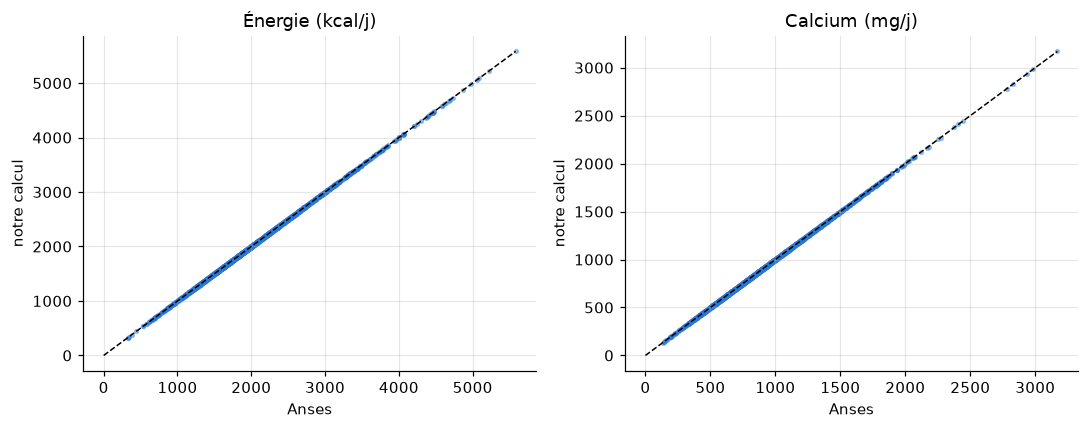

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, n in zip(axes, ["aet", "calcium"]):
    ax.scatter(comparaison[n + "_anses"], comparaison[n], s=6, alpha=0.4, color=C.PALETTE[0])
    lim = [0, comparaison[n].max()]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(title=f"{C.NUTRIMENTS[n][0]} ({C.NUTRIMENTS[n][1]}/j)", xlabel="Anses", ylabel="notre calcul")
plt.tight_layout()
plt.savefig(C.DOSSIER_FIGURES / "03_validation_anses.png", bbox_inches="tight")
plt.show()

**Conclusion** : nos apports sont **identiques** à ceux de l'Anses pour les 9 nutriments et les 2 121 adultes. Le pipeline (lecture, sélection, formule, prise en compte de `R24_pond`) est donc validé.

À noter : si on utilise `qte_conso` au lieu de `qte_conso_pond`, les écarts atteignent 1 à 7 % selon les nutriments. La pondération semaine / week-end compte vraiment.

➡️ Suite : `04_analyses.ipynb`